# Perfiles de generación solar y eólica

Construcción, verificación y figuras de los perfiles de disponibilidad que deben entrar al modelo.

- **Solar.** Generación fotovoltaica horaria oficial del **Explorador Solar** (Ministerio de Energía / DGF Universidad de Chile), 2004 a 2016, con los parámetros por defecto del Explorador: panel fijo inclinado a 38° hacia el norte, pérdidas 14 %, inversor 96 %, coeficiente de temperatura −0,45 %/°C, modelo PVWatts. Se descargó con el servicio del propio Explorador (`Proyecto oficial/Inputs/explorador_solar/`).
- **Eólico.** Serie de 8.760 h del `.nc` de Arauco (viento sostenido de Open-Meteo 2024 con ajuste ARClim), el mismo viento que genera las fallas, pasada por la curva de potencia de un aerogenerador genérico (cut-in 3, nominal 12, cut-out 25 m/s, buje a 30 m).

Las series se usan con el reloj de cada fuente, sin ajuste de horario. Exporta a `Tesis_Francisca_Muñoz_M/Figuras/Resultados/` (prefijo `perfil_`) y copias para presentación en `figuras_presentacion_perfiles/`.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt

from construir_perfiles import cf_eolico, V_CUT_IN, V_RATED, V_CUT_OUT, ALTURA_BUJE_M, ALTURA_MEDICION_M, EXP_HELLMANN

APP = Path.cwd()
ART = APP / 'artefactos'
EXPLORADOR = APP.parent / 'Proyecto oficial' / 'Inputs' / 'explorador_solar'
NC_CLIMA = APP.parent / 'Proyecto oficial' / 'Outputs' / 'BaseHoraEWE_arauco.nc'
OPENMETEO_CSV = APP.parent / 'Proyecto oficial' / 'Outputs' / 'Hourlyhistoricdata_openmeteo_long.csv'
TESIS = APP.parents[3] / 'Tesis_Francisca_Muñoz_M' / 'Figuras' / 'Resultados'
PRESENTACION = APP / 'figuras_presentacion_perfiles'

ZONAS = {1: 'Z1_Lebu_costera', 2: 'Z2_Arauco_costa_sur', 3: 'Z3_Lebu_interior'}
NOMBRE_ZONA = {1: 'Zona 1 · Lebú costera', 2: 'Zona 2 · Arauco costa sur', 3: 'Zona 3 · Lebú interior'}
PUNTO_OPENMETEO = {1: 0, 2: 1, 3: 2}   # point_id del csv de Open-Meteo

def leer_pv(z):
    d = pd.read_csv(EXPLORADOR / f'explorador_PV_{ZONAS[z]}.csv', skiprows=54, parse_dates=['Fecha/Hora'])
    return d.rename(columns={'Fecha/Hora': 'time'}).set_index('time')

PV = {z: leer_pv(z) for z in ZONAS}
RESUMEN = {z: json.loads((EXPLORADOR / f'explorador_PVSimple_resumen_{ZONAS[z]}.json').read_text(encoding='utf-8')) for z in ZONAS}
for z, d in PV.items():
    print(f"{NOMBRE_ZONA[z]}: {len(d)} h, {d.index.min()} a {d.index.max()}, pv faltante {d['pv'].isna().mean():.2%}, "
          f"FP informado por el Explorador {RESUMEN[z]['FP']}")

Zona 1 · Lebú costera: 113952 h, 2004-01-01 00:00:00 a 2016-12-30 23:00:00, pv faltante 0.08%, FP informado por el Explorador 0.16
Zona 2 · Arauco costa sur: 113952 h, 2004-01-01 00:00:00 a 2016-12-30 23:00:00, pv faltante 0.08%, FP informado por el Explorador 0.16
Zona 3 · Lebú interior: 113952 h, 2004-01-01 00:00:00 a 2016-12-30 23:00:00, pv faltante 0.08%, FP informado por el Explorador 0.15


In [2]:
# ── Estilo común (editar aquí) ──────────────────────────────────────────────
COLOR_ZONA = {1: '#3B82F6', 2: '#F59E0B', 3: '#10B981'}            # mismos colores del grafo
ESTILO_ZONA = {1: '-', 2: '-', 3: '-'}
TINTA, TINTA_2, MUTE, GRID = '#0b0b0b', '#52514e', '#898781', '#e3e2de'
GRIS_PRES = '#6b6b78'
MESES = list('EFMAMJJASOND')

mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.size': 9, 'axes.titlesize': 11, 'axes.labelsize': 9,
    'axes.titleweight': 'normal', 'axes.titlelocation': 'center',
    'axes.edgecolor': MUTE, 'axes.labelcolor': TINTA_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTE, 'ytick.color': MUTE, 'text.color': TINTA,
    'grid.color': GRID, 'grid.linewidth': 0.6,
    'legend.frameon': False, 'legend.fontsize': 8.5, 'lines.linewidth': 1.8,
})

def copia_presentacion(fig, nombre):
    PRESENTACION.mkdir(parents=True, exist_ok=True)
    fig.patch.set_alpha(0)
    for ax in fig.axes:
        ax.patch.set_alpha(0)
        for t in [ax.xaxis.label, ax.yaxis.label, ax.title, *ax.get_xticklabels(), *ax.get_yticklabels(), *ax.texts]:
            t.set_color(GRIS_PRES)
        for s in ax.spines.values():
            s.set_color(GRIS_PRES)
        ax.tick_params(colors=GRIS_PRES)
    for leyenda in [ax.get_legend() for ax in fig.axes if ax.get_legend()] + list(fig.legends):
        marco = leyenda.get_frame()
        marco.set_visible(True); marco.set_facecolor('white'); marco.set_edgecolor('white'); marco.set_alpha(1)
    for ext in ('png', 'svg'):
        fig.savefig(PRESENTACION / f'{nombre}.{ext}', facecolor='none')

def guardar(fig, nombre):
    TESIS.mkdir(parents=True, exist_ok=True)
    fig.savefig(TESIS / f'{nombre}.pdf')
    fig.savefig(TESIS / f'{nombre}.png')
    copia_presentacion(fig, nombre)
    print('→', nombre)

def eje(ancho=5.4, alto=3.6):
    fig, ax = plt.subplots(figsize=(ancho, alto))
    ax.grid(True, axis='y'); ax.set_axisbelow(True)
    return fig, ax

## 1. Perfil solar de 8.760 h desde el Explorador

La serie del Explorador (kWh por kWp instalado en cada hora, es decir, factor de planta horario) se promedia por **día del año y hora** sobre 2004 a 2016, igual que `construir_perfiles.climatologia_horaria`, y se lleva al calendario de 2030. Así se conserva la estacionalidad y el ciclo diario sin arrastrar el ruido de un año puntual.

Verificación: el factor de planta medio del perfil debe coincidir con el que informa el propio Explorador, y la energía mensual con su tabla de promedios mensuales.

In [3]:
from construir_perfiles import climatologia_horaria

SOLAR_EXPLORADOR = np.zeros((8760, 3))
verif = []
for i, z in enumerate(ZONAS):
    d = PV[z]['pv'].clip(lower=0)
    d = d[~((d.index.month == 2) & (d.index.day == 29))].dropna()
    SOLAR_EXPLORADOR[:, i] = climatologia_horaria(d.index, d.values, 8760, 2030)
    mensual_perfil = pd.Series(SOLAR_EXPLORADOR[:, i], index=pd.date_range('2030-01-01', periods=8760, freq='h')).resample('MS').sum()
    mensual_expl = np.array(RESUMEN[z]['PM']['Pac'])
    verif.append({'Zona': NOMBRE_ZONA[z],
                  'FP perfil 8760 h': round(float(SOLAR_EXPLORADOR[:, i].mean()), 4),
                  'FP serie 2004-2016': round(float(d.mean()), 4),
                  'FP informado Explorador': RESUMEN[z]['FP'],
                  'Energía anual perfil [kWh/kWp]': round(float(SOLAR_EXPLORADOR[:, i].sum()), 0),
                  'Energía anual Explorador [kWh/kWp]': RESUMEN[z]['TA'],
                  'Error mensual máx. [%]': round(float(np.max(np.abs(mensual_perfil.values / mensual_expl - 1)) * 100), 1),
                  'Máx. horario': round(float(SOLAR_EXPLORADOR[:, i].max()), 3)})
    assert 0 <= SOLAR_EXPLORADOR[:, i].min() and SOLAR_EXPLORADOR[:, i].max() <= 1.0

np.savez_compressed(EXPLORADOR / 'perfil_solar_explorador_8760.npz', solar_por_zona=SOLAR_EXPLORADOR,
                    zonas=np.array(list(ZONAS)), fuente='Explorador Solar DHC_PV 2004-2016, climatologia (doy, hora)')
pd.DataFrame(verif)

,Zona,FP perfil 8760 h,FP serie 2004-2016,FP informado Explorador,Energía anual perfil [kWh/kWp],Energía anual Explorador [kWh/kWp],Error mensual máx. [%],Máx. horario
0,Zona 1 · Lebú costera,0.1566,0.1566,0.16,1372.0,1371.76,0.7,0.757
1,Zona 2 · Arauco costa sur,0.1555,0.1555,0.16,1362.0,1362.01,0.6,0.770
2,Zona 3 · Lebú interior,0.1489,0.1489,0.15,1305.0,1304.61,0.6,0.754


→ perfil_solar_explorador_dia


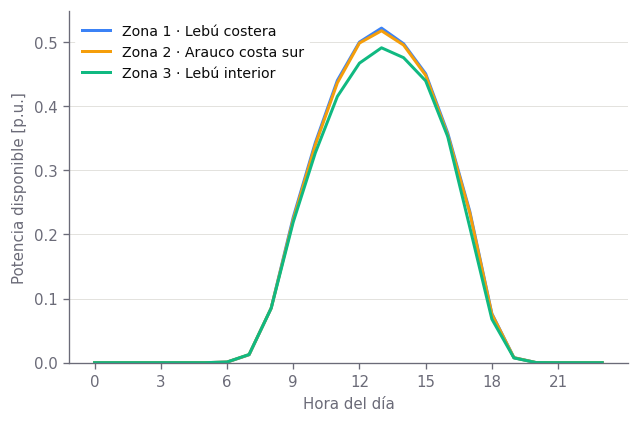

→ perfil_solar_explorador_mes


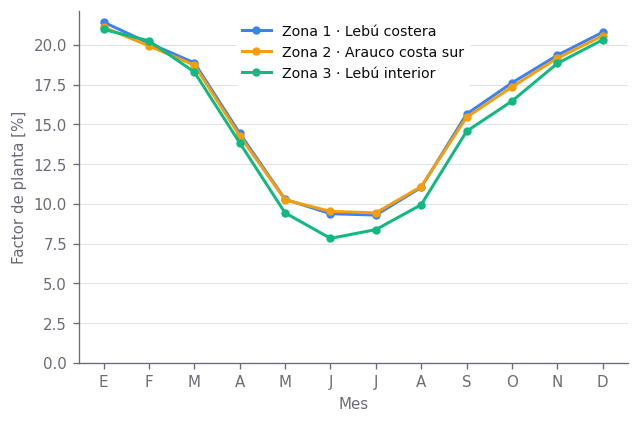

In [4]:
T2030 = pd.date_range('2030-01-01', periods=8760, freq='h')

def dia_medio(v):  return pd.Series(v, index=T2030).groupby(T2030.hour).mean()
def mensual(v):    return pd.Series(v, index=T2030).groupby(T2030.month).mean()

# ── Figura: día medio por zona (Explorador) ──
fig, ax = eje()
for i, z in enumerate(ZONAS):
    s = dia_medio(SOLAR_EXPLORADOR[:, i])
    ax.plot(s.index, s.values, color=COLOR_ZONA[z], ls=ESTILO_ZONA[z], label=NOMBRE_ZONA[z])
ax.set(xlabel='Hora del día', ylabel='Potencia disponible [p.u.]', xticks=range(0, 24, 3), ylim=(0, None))
ax.legend(loc='upper left')
fig.tight_layout(); guardar(fig, 'perfil_solar_explorador_dia'); plt.show()

# ── Figura: media mensual por zona (Explorador) ──
fig, ax = eje()
for i, z in enumerate(ZONAS):
    s = mensual(SOLAR_EXPLORADOR[:, i])
    ax.plot(s.index, s.values * 100, color=COLOR_ZONA[z], ls=ESTILO_ZONA[z], marker='o', ms=4, label=NOMBRE_ZONA[z])
ax.set(xlabel='Mes', ylabel='Factor de planta [%]', xticks=range(1, 13), ylim=(0, None))
ax.set_xticklabels(MESES)
ax.legend(loc='upper center')
fig.tight_layout(); guardar(fig, 'perfil_solar_explorador_mes'); plt.show()

→ perfil_solar_explorador_anual


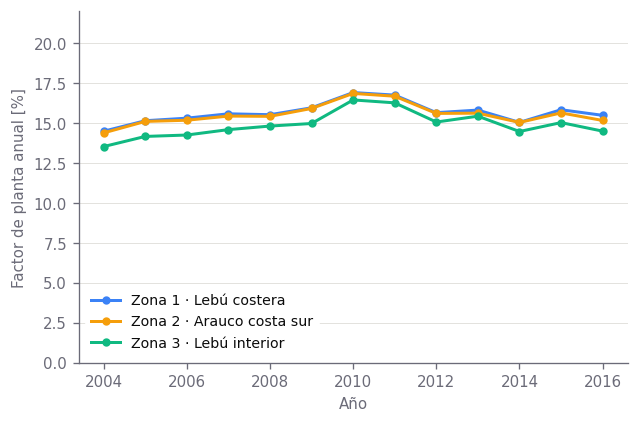

→ perfil_solar_explorador_mapa_z1


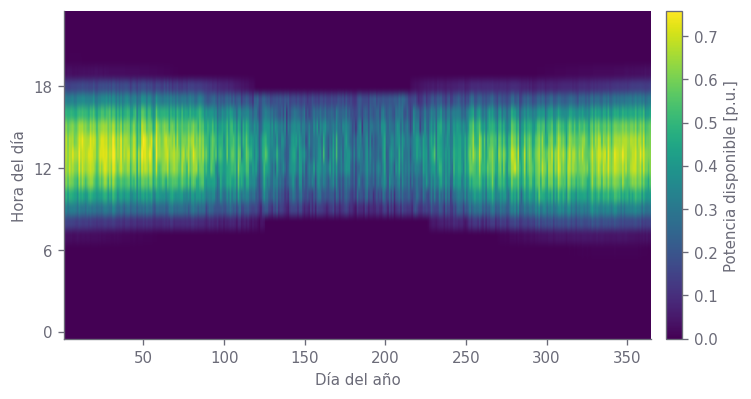

In [5]:
# ── Figura: variabilidad entre años del factor de planta solar (Explorador 2004-2016) ──
fig, ax = eje()
anual_solar = {}
for z in ZONAS:
    s = PV[z]['pv'].clip(lower=0)
    a = s.groupby(s.index.year).mean()
    a = a[s.groupby(s.index.year).size() >= 8700]       # solo años completos
    anual_solar[z] = a
    ax.plot(a.index, a.values * 100, color=COLOR_ZONA[z], ls=ESTILO_ZONA[z], marker='o', ms=4, label=NOMBRE_ZONA[z])
ax.set(xlabel='Año', ylabel='Factor de planta anual [%]', ylim=(0, 22))
ax.legend(loc='lower left')
fig.tight_layout(); guardar(fig, 'perfil_solar_explorador_anual'); plt.show()
pd.DataFrame({NOMBRE_ZONA[z]: a.round(3) for z, a in anual_solar.items()}).T

# ── Figura: perfil 8760 h de la zona 1 como mapa hora × día ──
fig, ax = plt.subplots(figsize=(6.6, 3.4))
mapa = SOLAR_EXPLORADOR[:, 0].reshape(365, 24).T
im = ax.imshow(mapa, aspect='auto', origin='lower', cmap='viridis', vmin=0, vmax=max(0.75, mapa.max()),
               extent=[1, 365, -0.5, 23.5])
ax.set(xlabel='Día del año', ylabel='Hora del día', yticks=range(0, 24, 6))
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label('Potencia disponible [p.u.]', color=TINTA_2)
fig.tight_layout(); guardar(fig, 'perfil_solar_explorador_mapa_z1'); plt.show()

## 2. Perfil eólico

El perfil eólico que corresponde es la **serie de 8.760 h** del `.nc`, no una curva típica: es el mismo viento que sortea las fallas, de modo que la turbina y las líneas ven el mismo evento. Se usa el viento **sostenido** (media horaria), que es el estadístico sobre el que se define la curva de potencia; la ráfaga se reserva para la curva de fragilidad.

In [6]:
ds = xr.open_dataset(NC_CLIMA)
fila = {int(z): i for i, z in enumerate(ds['zone_id'].values)}
FACTOR_BUJE = (ALTURA_BUJE_M / ALTURA_MEDICION_M) ** EXP_HELLMANN
V10 = {z: np.asarray(ds['wind'].values[8760:17520, fila[z], 0], float) for z in ZONAS}          # sostenido 10 m
V10_RAF = {z: np.asarray(ds['wind'].values[8760:17520, fila[z], 1], float) for z in ZONAS}      # ráfaga 10 m
EOLICO = np.column_stack([cf_eolico(V10[z]) for z in ZONAS])
assert np.allclose(EOLICO, np.load(ART / 'perfiles_horarios.npz')['eolico_por_zona'])

resumen_eol = []
for i, z in enumerate(ZONAS):
    vb, vr = V10[z] * FACTOR_BUJE, V10_RAF[z] * FACTOR_BUJE
    resumen_eol.append({'Zona': NOMBRE_ZONA[z], 'FP 8760 h': round(float(EOLICO[:, i].mean()), 3),
                        'v media buje [m/s]': round(float(vb.mean()), 2), 'v máx buje [m/s]': round(float(vb.max()), 1),
                        'h bajo cut-in': int((vb < V_CUT_IN).sum()), 'h a potencia nominal': int(((vb >= V_RATED) & (vb <= V_CUT_OUT)).sum()),
                        'h sobre cut-out (sostenido)': int((vb > V_CUT_OUT).sum()),
                        'h sobre cut-out (si se usara ráfaga)': int((vr > V_CUT_OUT).sum())})
pd.DataFrame(resumen_eol)

,Zona,FP 8760 h,v media buje [m/s],v máx buje [m/s],h bajo cut-in,h a potencia nominal,h sobre cut-out (sostenido),h sobre cut-out (si se usara ráfaga)
0,Zona 1 · Lebú costera,0.222,6.16,21.6,1687,351,0,137
1,Zona 2 · Arauco costa sur,0.219,6.09,22.3,1790,351,0,110
2,Zona 3 · Lebú interior,0.103,4.72,18.1,2611,51,0,29


→ perfil_eolico_curva_potencia


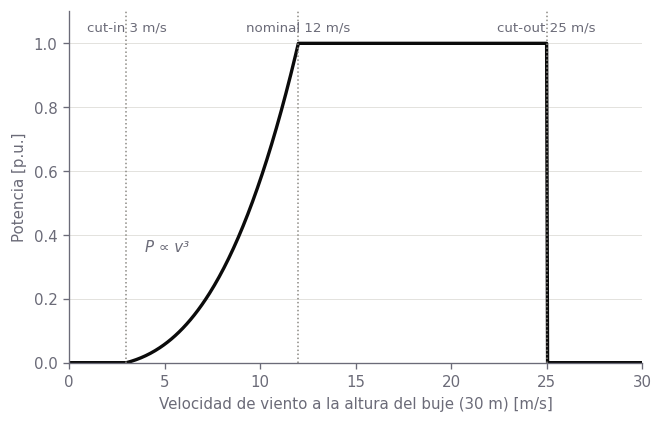

→ perfil_eolico_distribucion_viento


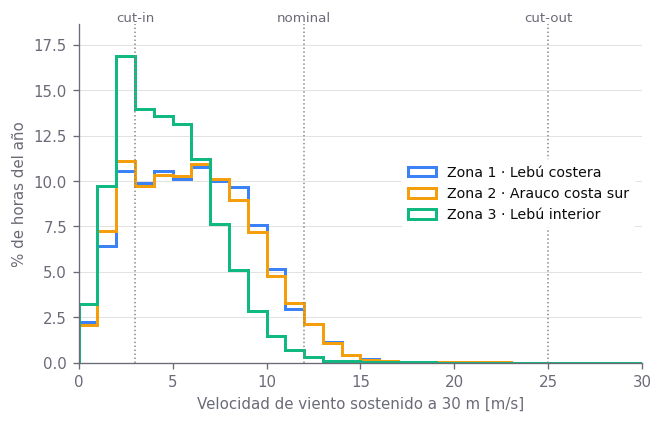

In [7]:
# ── Figura: curva de potencia del aerogenerador ──
v = np.linspace(0, 30, 601)
cf_curva = cf_eolico(v / FACTOR_BUJE)          # la curva recibe viento a 10 m
fig, ax = eje(5.6, 3.6)
ax.plot(v, cf_curva, color=TINTA, lw=2)
for x, txt in ((V_CUT_IN, f'cut-in {V_CUT_IN:.0f} m/s'), (V_RATED, f'nominal {V_RATED:.0f} m/s'), (V_CUT_OUT, f'cut-out {V_CUT_OUT:.0f} m/s')):
    ax.axvline(x, color=MUTE, lw=0.9, ls=':')
    ax.annotate(txt, (x, 1.04), ha='center', fontsize=8, color=TINTA_2, annotation_clip=False)
ax.annotate('P ∝ v³', (6.3, 0.35), fontsize=9, color=TINTA_2, style='italic', ha='right')
ax.set(xlabel=f'Velocidad de viento a la altura del buje ({ALTURA_BUJE_M:.0f} m) [m/s]', ylabel='Potencia [p.u.]',
       xlim=(0, 30), ylim=(0, 1.1))
fig.tight_layout(); guardar(fig, 'perfil_eolico_curva_potencia'); plt.show()

# ── Figura: distribución del viento sostenido a la altura del buje frente a la curva ──
fig, ax = eje(5.6, 3.6)
bins = np.arange(0, 31, 1)
for z in ZONAS:
    vb = V10[z] * FACTOR_BUJE
    ax.hist(vb, bins=bins, weights=np.full(vb.size, 100 / vb.size), histtype='step', lw=1.8,
            color=COLOR_ZONA[z], ls=ESTILO_ZONA[z], label=NOMBRE_ZONA[z])
y_max = ax.get_ylim()[1] * 1.05
for x, txt in ((V_CUT_IN, 'cut-in'), (V_RATED, 'nominal'), (V_CUT_OUT, 'cut-out')):
    ax.axvline(x, color=MUTE, lw=0.9, ls=':')
    ax.annotate(txt, (x, y_max), ha='center', va='bottom', fontsize=8, color=TINTA_2, annotation_clip=False)
ax.set(xlabel=f'Velocidad de viento sostenido a {ALTURA_BUJE_M:.0f} m [m/s]', ylabel='% de horas del año', xlim=(0, 30), ylim=(0, y_max))
ax.legend(loc='center right')
fig.tight_layout(); guardar(fig, 'perfil_eolico_distribucion_viento'); plt.show()

→ perfil_eolico_serie_anual


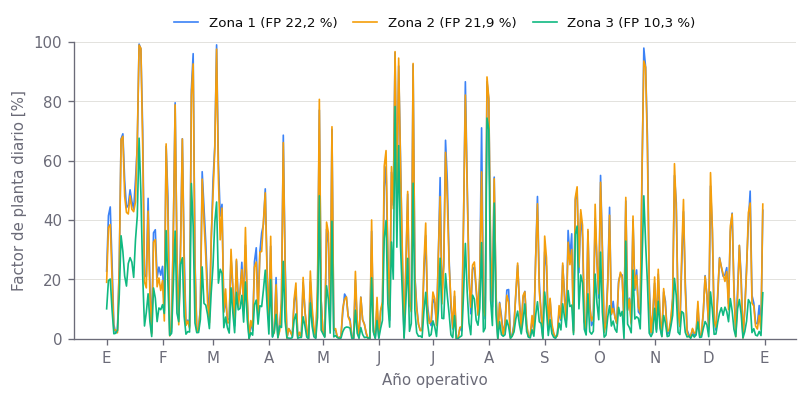

→ perfil_eolico_anual


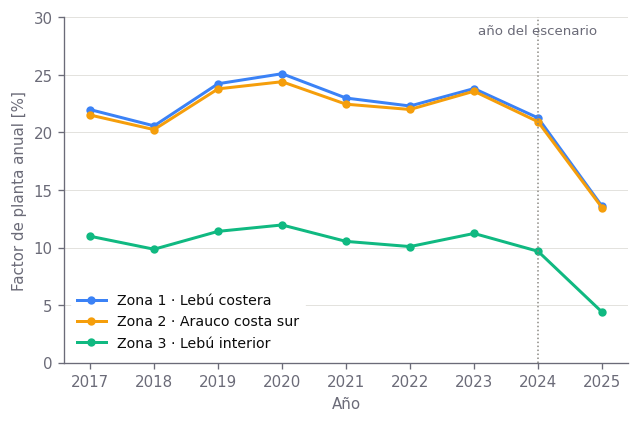

Horas por año en el csv de Open-Meteo: {2017: 8760, 2018: 8760, 2019: 8760, 2020: 8784, 2021: 8760, 2022: 8760, 2023: 8760, 2024: 8784, 2025: 8760}


time,2017,2018,2019,2020,2021,2022,2023,2024,2025
Zona 1 · Lebú costera,0.220,0.206,0.242,0.251,0.230,0.223,0.238,0.213,0.136
Zona 2 · Arauco costa sur,0.215,0.203,0.238,0.244,0.225,0.220,0.236,0.209,0.135
Zona 3 · Lebú interior,0.110,0.099,0.114,0.120,0.105,0.101,0.112,0.097,0.044


In [8]:
# ── Figura: serie anual de 8760 h del factor de planta eólico (media diaria) ──
fig, ax = eje(6.8, 3.4)
for i, z in enumerate(ZONAS):
    s = pd.Series(EOLICO[:, i], index=T2030).resample('D').mean()
    ax.plot(s.index, s.values * 100, color=COLOR_ZONA[z], ls=ESTILO_ZONA[z], lw=1.0, label=f'Zona {z} (FP {EOLICO[:, i].mean() * 100:.1f} %)'.replace('.', ','))
ax.set(xlabel='Año operativo', ylabel='Factor de planta diario [%]', ylim=(0, 100))
ax.xaxis.set_major_locator(mpl.dates.MonthLocator())
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda x, _: MESES[mpl.dates.num2date(x).month - 1]))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8, columnspacing=1.2, handlelength=1.8)
fig.tight_layout(); guardar(fig, 'perfil_eolico_serie_anual'); plt.show()

# ── Figura: variabilidad entre años del factor de planta eólico (Open-Meteo 2017-2024) ──
om = pd.read_csv(OPENMETEO_CSV, parse_dates=['time'])
fig, ax = eje()
anual_eol = {}
for z in ZONAS:
    s = om[om['point_id'] == PUNTO_OPENMETEO[z]].set_index('time')['wind']
    fp = pd.Series(cf_eolico(s.to_numpy()), index=s.index)
    horas = fp.groupby(fp.index.year).size()
    a = fp.groupby(fp.index.year).mean()[horas >= 8700]
    anual_eol[z] = a
    ax.plot(a.index, a.values * 100, color=COLOR_ZONA[z], ls=ESTILO_ZONA[z], marker='o', ms=4, label=NOMBRE_ZONA[z])
ax.axvline(2024, color=MUTE, lw=0.9, ls=':')
ax.annotate('año del escenario', (2024, 28.5), ha='center', fontsize=8, color=TINTA_2)
ax.set(xlabel='Año', ylabel='Factor de planta anual [%]', ylim=(0, 30))
ax.legend(loc='lower left')
fig.tight_layout(); guardar(fig, 'perfil_eolico_anual'); plt.show()
print('Horas por año en el csv de Open-Meteo:', om[om['point_id'] == 0].groupby(om['time'].dt.year).size().to_dict())
pd.DataFrame({NOMBRE_ZONA[z]: a.round(3) for z, a in anual_eol.items()}).T